# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple

   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        # X = np.asarray(X, dtype=float)
        X = np.c_[np.ones(len(X)), X]
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)

        self.w = np.zeros(X.shape[1]) if self.w0 is None else np.array(self.w0, dtype=float).copy()

        for i in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'full':
                grad = self.calc_gradient(X, y)
            else:
                idx = rng.choice(len(y), self.batch_size, replace=False)
                grad = self.calc_gradient(X[idx], y[idx])
            new_w = self.w - self.eta * grad
            step = np.linalg.norm(new_w - self.w)
            self.w = new_w
            if step < self.tolerance:
                break

        return self

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        p = self.sigmoid(np.c_[np.ones(len(X)), X] @ self.w)
        return np.c_[1 - p, p]

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        z = X @ self.w
        return np.mean(np.logaddexp(0, z) - y * z)

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 3.27e-11


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

GD итераций: 1000 loss: 0.51245
SGD итераций: 1000 loss: 0.51293


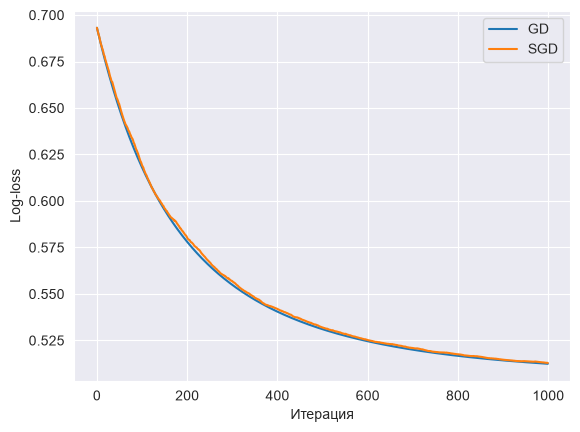

In [6]:
model_gd = LogReg(gd_type='full').fit(X_train, y_train)
model_sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
for name, model in [('GD', model_gd), ('SGD', model_sgd)]:
    print(name, 'итераций:', len(model.loss_history), 'loss:', round(model.loss_history[-1], 5))
    plt.plot(model.loss_history, label=name)
plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.legend()
plt.show()

Обе модели сделали по `1000` обновлений и остановились по `max_iter`. Последний loss полного GD равен `0.51245`, а SGD `0.51293` . Полный GD просматривает за обновление все 14000
обучающих объектов, мини-батч SGD только `32`. Из-за случайного
состава батчей у SGD градиент и величина шага колеблются, при постоянной
скорости обучения условие `||w_{k+1} - w_k|| < tolerance` срабатывает
реже. Графики показывают более гладкую кривую полного GD.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

eta=0.001: 1000 итераций, loss=0.61814
eta=0.01: 1000 итераций, loss=0.51245
eta=0.1: 465 итераций, loss=0.50576
eta=1: 70 итераций, loss=0.50576
eta=10: 1000 итераций, loss=0.94581


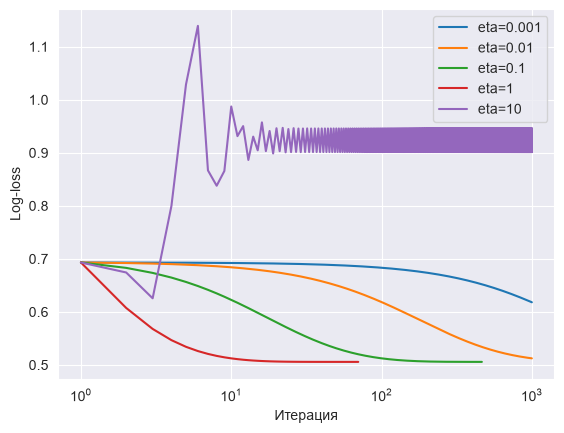

In [7]:
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(eta=eta).fit(X_train, y_train)
    print(f'eta={eta:g}: {len(model.loss_history)} итераций, loss={model.loss_history[-1]:.5f}')
    plt.plot(range(1, len(model.loss_history) + 1), model.loss_history, label=f'eta={eta:g}')
plt.xscale('log')
plt.xlabel('Итерация')
plt.ylabel('Log-loss')
plt.legend()
plt.show()

При маленьких `eta` сходимость медленная: loss равен 0.61814 при
`eta=0.001` и 0.51245 при `eta=0.01`. При `eta=0.1` и `eta=1` модель
останавливается через 465 и 70 итераций, loss около 0.50576.
Большой шаг `eta=10` ведёт себя хуже (loss около 0.94581).

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
sk_model = LogisticRegression(random_state=42).fit(X_train, y_train)
rows = []
for name, model in [('GD', model_gd), ('SGD', model_sgd), ('sklearn', sk_model)]:
    rows.append([name, metrics.accuracy_score(y_test, model.predict(X_test)),
                 metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])])
display(pd.DataFrame(rows, columns=['Модель', 'Accuracy', 'ROC-AUC']).round(4))

sk_w = np.r_[sk_model.intercept_, sk_model.coef_.ravel()]
display(pd.DataFrame({'Мой GD': model_gd.w, 'sklearn': sk_w,
                      'Разница': model_gd.w - sk_w}).round(4))

,Модель,Accuracy,ROC-AUC
0,GD,0.7820,0.8388
1,SGD,0.7825,0.8381
2,sklearn,0.7765,0.8387


,Мой GD,sklearn,Разница
0,-0.0021,-0.0219,0.0198
1,0.0061,0.0027,0.0033
2,0.0070,0.0090,-0.0021
3,-0.5472,-0.7227,0.1755
4,-0.1445,-0.2623,0.1178
5,0.0125,0.0166,-0.0041
6,-0.0063,-0.0115,0.0052
7,0.0008,0.0056,-0.0048
8,0.0391,0.0572,-0.0181
9,-0.0024,-0.0012,-0.0012


Метрики моделей близки, но веса отличаются. Наша модель делает
1000 шагов с `eta=0.01` и не использует регуляризацию. В `sklearn`
регуляризация L2 включена по умолчанию. Для аналогичной задачи оптимизации
можно задать `LogisticRegression(penalty=None)` и обучить собственный GD до сходимости.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [12]:
print('Пропущенных значений по столбцам:')
print(df.isna().sum().to_string())
print('Полных дубликатов строк:', int(df.duplicated().sum()))
print(f'Доля хороших вин на train: {y_train.mean():.4f}')
print(f'Доля хороших вин на test:  {y_test.mean():.4f}')

naive_pred = np.zeros(len(y_test), dtype=int)
naive_accuracy = metrics.accuracy_score(y_test, naive_pred)
wine_base = make_pipeline(StandardScaler(),
                          LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
wine_base.fit(X_train, y_train)
base_accuracy = metrics.accuracy_score(y_test, wine_base.predict(X_test))
print(f'Accuracy всегда 0: {naive_accuracy:.4f}')
print(f'Accuracy логистической регрессии: {base_accuracy:.4f}')


Пропущенных значений по столбцам:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
target                  0
Полных дубликатов строк: 1177
Доля хороших вин на train: 0.1966
Доля хороших вин на test:  0.1964
Accuracy всегда 0: 0.8036
Accuracy логистической регрессии: 0.8200


Все признаки заполнены, но обнаружено **1177 полных
дубликатов**. Это не обязательно ошибка измерения: разные образцы
могут иметь одинаковые характеристики. В рамках готового разбиения
оставляем строки как есть, но для оценки на действительно новых
уникальных винах повторы лучше устранить или сгруппировать ещё до
разделения данных иначе одинаковые объекты могут попасть в train и test.
`stratify=y` сохранил долю класса 1 около **19.66%** на обучении и
**19.64%** на тесте. Константная модель получает accuracy **80.36%**,
логистическая регрессия **82.00%**. Разница невелика, а константная
модель совершенно не находит хороших вин: accuracy маскирует дисбаланс.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

Наша матрица:
 [[1501   66]
 [ 285   98]]
Матрица sklearn:
 [[1501   66]
 [ 285   98]]


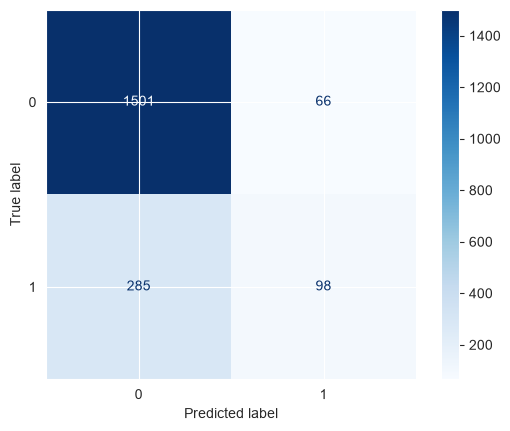

In [13]:
y_pred_base = wine_base.predict(X_test)
TP = np.sum((y_test == 1) & (y_pred_base == 1))
TN = np.sum((y_test == 0) & (y_pred_base == 0))
FP = np.sum((y_test == 0) & (y_pred_base == 1))
FN = np.sum((y_test == 1) & (y_pred_base == 0))
cm = np.array([[TN, FP], [FN, TP]])
print('Наша матрица:\n', cm)
print('Матрица sklearn:\n', metrics.confusion_matrix(y_test, y_pred_base))
metrics.ConfusionMatrixDisplay(cm).plot(cmap='Blues')
plt.show()

Матрица ошибок: `TN=1501`, `FP=66`, `FN=285`, `TP=98`.
Для сервиса `FP` означает, что клиенту предложили вино с оценкой ниже 7,
`FN` что действительно хорошее вино не попало в подборку.
Пропусков хороших вин (FN=285) заметно больше, чем ложных
рекомендаций (FP=66). Строки матрицы соответствуют реальным классам,
столбцы предсказанным.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [14]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
print('Precision:', precision, 'sklearn:', metrics.precision_score(y_test, y_pred_base))
print('Recall:', recall, 'sklearn:', metrics.recall_score(y_test, y_pred_base))
for beta in [0.5, 1, 2]:
    f = (1 + beta**2) * precision * recall / (beta**2 * precision + recall)
    print(f'F{beta}: {f:.4f}, sklearn: {metrics.fbeta_score(y_test, y_pred_base, beta=beta):.4f}')

Precision: 0.5975609756097561 sklearn: 0.5975609756097561
Recall: 0.2558746736292428 sklearn: 0.2558746736292428
F0.5: 0.4716, sklearn: 0.4716
F1: 0.3583, sklearn: 0.3583
F2: 0.2889, sklearn: 0.2889


Получилось precision **0.5976**, recall
**0.2559**, F0.5 **0.4716**, F1 **0.3583**, F2 **0.2889** всё совпало
с `sklearn`. Модель довольно осторожная: почти 60% рекомендованных вин
действительно хорошие, но она находит лишь 26% от всех хороших.
$F_{0.5}$ сильнее ценит **precision**, поэтому подходит, если подписчики
особенно не любят слабые рекомендации. $F_2$ акцентирует **recall**
и лучше отражает цель максимально широкой подборки.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

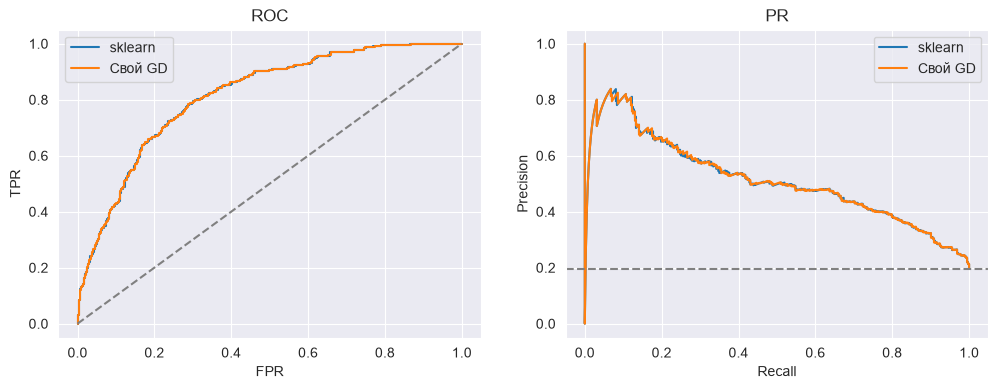

,Модель,ROC-AUC,PR-AUC (AP)
0,sklearn,0.8135,0.5121
1,Свой GD,0.8135,0.5122


p 0.8135
10p 0.8135
p^3 0.8135
logit(p) 0.8135
-p 0.1865
Метки 0/1 0.6069


In [15]:
wine_manual = make_pipeline(StandardScaler(), LogReg(eta=0.5, tolerance=1e-7,
                                                          max_iter=3500)).fit(X_train, y_train)
wine_scores = {'sklearn': wine_base.predict_proba(X_test)[:, 1],
               'Свой GD': wine_manual.predict_proba(X_test)[:, 1]}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rows = []
for name, p in wine_scores.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, p)
    prec, rec, _ = metrics.precision_recall_curve(y_test, p)
    rows.append([name, metrics.roc_auc_score(y_test, p),
                 metrics.average_precision_score(y_test, p)])
    ax[0].plot(fpr, tpr, label=name)
    ax[1].plot(rec, prec, label=name)
ax[0].plot([0, 1], [0, 1], '--', color='gray')
ax[1].axhline(y_test.mean(), ls='--', color='gray')
ax[0].set(title='ROC', xlabel='FPR', ylabel='TPR')
ax[1].set(title='PR', xlabel='Recall', ylabel='Precision')
for a in ax:
    a.legend()
plt.show()
display(pd.DataFrame(rows, columns=['Модель', 'ROC-AUC', 'PR-AUC (AP)']).round(4))

p = wine_scores['sklearn']
for name, score in [('p', p), ('10p', 10*p), ('p^3', p**3),
                    ('logit(p)', np.log(p/(1-p))), ('-p', -p),
                    ('Метки 0/1', wine_base.predict(X_test))]:
    print(name, round(metrics.roc_auc_score(y_test, score), 4))

Свой GD и `sklearn` практически одинаково ранжируют вина:
ROC-AUC у обеих примерно **0.8135**, average precision **0.5122**
и **0.5121**. У случайного ранжирования PR-базис равен prevalence
положительного класса (**0.1964**), а не 0.5.

ROC-AUC для `10p`, $p^3$ и `logit(p)` не меняется (**0.8135**):
возрастающие функции сохраняют порядок. Для `-p` он превращается
в **0.1865** (почти `1 - 0.8135`). Для жёстких меток 0/1  **0.6069**,
потому что оценка теряет различия между объектами внутри одного класса
предсказания. Здесь PR-AUC считали как **average precision (AP)**,
это не то же самое, что трапециевидная площадь под PR-кривой.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

Лучший порог F1: 0.268 Порог при recall>=0.7: 0.243


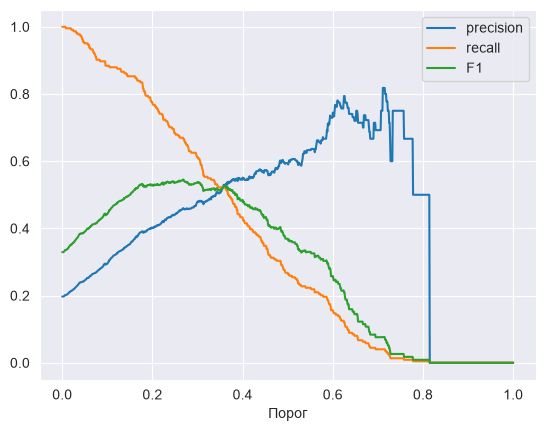

,Порог,Precision,Recall,F1
0,0.500,0.5976,0.2559,0.3583
1,0.268,0.4732,0.6449,0.5459
2,0.243,0.4370,0.6789,0.5317


In [16]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)
tuning_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_subtrain, y_subtrain)
p_val = tuning_model.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0, 1, 1001)
pred = p_val[None, :] >= thresholds[:, None]
tp = (pred & (y_val.to_numpy() == 1)).sum(axis=1)
fp = (pred & (y_val.to_numpy() == 0)).sum(axis=1)
prec = tp / np.maximum(tp + fp, 1)
rec = tp / y_val.sum()
f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
t_f1 = thresholds[np.argmax(f1)]
t_r = thresholds[rec >= 0.7][np.argmax(prec[rec >= 0.7])]
print('Лучший порог F1:', t_f1, 'Порог при recall>=0.7:', t_r)

for name, values in [('precision', prec), ('recall', rec), ('F1', f1)]:
    plt.plot(thresholds, values, label=name)
plt.xlabel('Порог')
plt.legend()
plt.show()

model_plain = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
p_test = model_plain.predict_proba(X_test)[:, 1]
rows = []
for t in [0.5, t_f1, t_r]:
    pred = (p_test >= t).astype(int)
    rows.append([t, metrics.precision_score(y_test, pred), metrics.recall_score(y_test, pred),
                 metrics.f1_score(y_test, pred)])
display(pd.DataFrame(rows, columns=['Порог', 'Precision', 'Recall', 'F1']).round(4))

На валидации оптимальный по F1 порог **0.268**
(F1 **0.5455**). Порог **0.243** максимизировал precision среди
вариантов с recall не ниже 0.7 на валидации. После повторного обучения
на всём train получаем на тесте:

1. `0.5`: precision **0.5976**, recall **0.2559**, F1 **0.3583**;
2. `t_F1=0.268`: precision **0.4732**, recall **0.6449**, F1 **0.5459**;
3. `t_R=0.243`: precision **0.4370**, recall **0.6789**, F1 **0.5317**.

Значит, recall $\ge$ 0.7 на тесте не выполнен, хотя на валидации он
был **0.7009**: выборки отличаются, поэтому конечная валидация не даёт
гарантии. Для первоначальной версии сервиса беру `t_F1` как компромисс,
а не пытаюсь подстроить порог под увиденные тестовые метрики.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [17]:
def score_pipeline(model, name, threshold=0.5):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= threshold).astype(int)
    return {'Модель': name, 'Порог': threshold,
            'accuracy': metrics.accuracy_score(y_test, pred),
            'precision': metrics.precision_score(y_test, pred),
            'recall': metrics.recall_score(y_test, pred),
            'F1': metrics.f1_score(y_test, pred),
            'ROC-AUC': metrics.roc_auc_score(y_test, p),
            'PR-AUC (AP)': metrics.average_precision_score(y_test, p)}

model_balanced = make_pipeline(StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight='balanced')).fit(X_train, y_train)
summary_rows = [score_pipeline(model_plain, 'Без весов'),
                score_pipeline(model_balanced, 'Веса balanced')]
display(pd.DataFrame(summary_rows).round(4))
print('Число объектов:', np.bincount(y_train))
print('Веса классов:', len(y_train) / (2 * np.bincount(y_train)))

,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
0,Без весов,0.5,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
1,Веса balanced,0.5,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005


Число объектов: [3653  894]
Веса классов: [0.62236518 2.54306488]


При `class_weight='balanced'` веса классов вычисляются
по формуле $w_c = N/(2N_c)$. В train объектов класса 0 - **3653**,
класса 1 - **894**, поэтому веса **0.6224** и **2.5431**.
Из-за большего веса редкого класса recall вырос с **0.2559** до
**0.7546**, а precision снизился с **0.5976** до **0.3970**.
Accuracy снизилась с **0.8200** до **0.7267**; ROC-AUC почти тот же
(**0.8135 -> 0.8113**), AP поменялся слабее (**0.5121 -> 0.5005**).
Веса изменили баланс FP/FN и немного само ранжирование.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [18]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=42),
            'NearMiss v2': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=42),
            'SMOTE': SMOTE(random_state=42)}
sampling_models = {}
X_scaled = StandardScaler().fit_transform(X_train)
for name, sampler in samplers.items():
    _, y_sampled = sampler.fit_resample(X_scaled, y_train)
    print(name, 'размеры классов:', np.bincount(y_sampled))
    model = make_imb_pipeline(StandardScaler(), sampler, LogisticRegression(max_iter=1000))
    model.fit(X_train, y_train)
    sampling_models[name] = model
    summary_rows.append(score_pipeline(model, name))
display(pd.DataFrame(summary_rows).round(4))

other_order = make_imb_pipeline(SMOTE(random_state=42), StandardScaler(),
                                LogisticRegression(max_iter=1000)).fit(X_train, y_train)
display(pd.DataFrame([score_pipeline(sampling_models['SMOTE'], 'Сначала scaler'),
                      score_pipeline(other_order, 'Сначала SMOTE')]).round(4))

RandomUnderSampler размеры классов: [894 894]
NearMiss v2 размеры классов: [894 894]
RandomOverSampler размеры классов: [3653 3653]
SMOTE размеры классов: [3653 3653]


,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
0,Без весов,0.5,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
1,Веса balanced,0.5,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
2,RandomUnderSampler,0.5,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
3,NearMiss v2,0.5,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001
4,RandomOverSampler,0.5,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
5,SMOTE,0.5,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040


,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
0,Сначала scaler,0.5,0.7292,0.3992,0.7493,0.5209,0.8125,0.504
1,Сначала SMOTE,0.5,0.7338,0.4042,0.7493,0.5252,0.8116,0.509


Случайное уменьшение и `NearMiss` сократили оба класса
до **894** объектов, а `RandomOverSampler` и `SMOTE` довели их до
**3653** каждого. Нужен именно `imblearn.pipeline`: у него sampler
работает только на этапе `fit`, а тестовую выборку `predict` не меняет.
Балансировка до разделения train/test привела бы к утечке данных.

Среди четырёх методов лучший PR-AUC (AP) дал **SMOTE: 0.5040**, худший
**NearMiss v2: 0.4001**. NearMiss агрессивно отбирает ближайшие объекты
большинства и может исказить обучающую выборку. У SMOTE и NearMiss
важен масштаб признаков, поскольку используются расстояния между точками.
Мы проверили порядок SMOTE: **0.5040** AP при масштабировании сначала
против **0.5090** при SMOTE сначала. Это не значит, что второй вариант
всегда лучше для корректного сравнения порядок выбирают на валидации.
У случайных under/over-sampling выбор строк не зависит от масштаба,
но итоговая стандартизация после балансировки может изменить коэффициенты.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

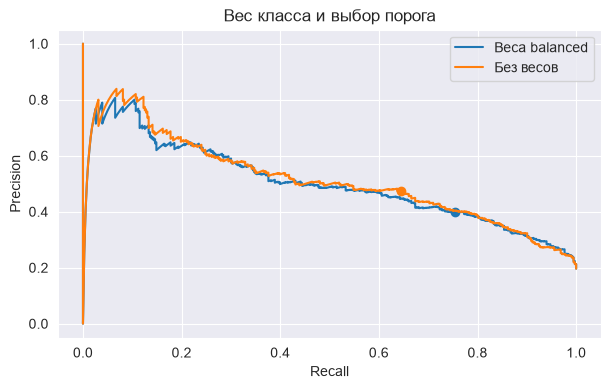

,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
0,balanced,0.500,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
1,Порог F1,0.268,0.7892,0.4732,0.6449,0.5459,0.8135,0.5121


In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, model, t in [('Веса balanced', model_balanced, 0.5),
                       ('Без весов', model_plain, t_f1)]:
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= t).astype(int)
    prec, rec, _ = metrics.precision_recall_curve(y_test, p)
    ax.plot(rec, prec, label=name)
    ax.scatter(metrics.recall_score(y_test, pred), metrics.precision_score(y_test, pred))
ax.set(xlabel='Recall', ylabel='Precision', title='Вес класса и выбор порога')
ax.legend()
plt.show()
display(pd.DataFrame([score_pipeline(model_balanced, 'balanced'),
                      score_pipeline(model_plain, 'Порог F1', t_f1)]).round(4))

Модель с `balanced` и порогом 0.5: precision **0.3970**,
recall **0.7546**, F1 **0.5203**. Модель без весов с валидационным
`t_F1=0.268`: precision **0.4732**, recall **0.6449**, F1 **0.5459**.
По форме PR-кривые похожи, но не совпадают: AP **0.5005** против
**0.5121**. Сдвиг порога нередко воспроизводит похожий баланс
precision/recall, однако веса также меняют коэффициенты и порядок
предсказанных вероятностей. Поэтому "взвешивание только двигает порог"
полезная интуиция, но не математическое тождество.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [23]:
results = summary_rows + [score_pipeline(wine_manual, 'Свой GD'),
                          score_pipeline(model_plain, 'Порог F1', t_f1),
                          score_pipeline(model_plain, 'Порог R', t_r)]
display(pd.DataFrame(results).sort_values('PR-AUC (AP)', ascending=False).round(4))
final_model = model_plain
final_threshold = t_f1

,Модель,Порог,accuracy,precision,recall,F1,ROC-AUC,PR-AUC (AP)
6,Свой GD,0.500,0.8221,0.6071,0.2663,0.3702,0.8135,0.5122
0,Без весов,0.500,0.8200,0.5976,0.2559,0.3583,0.8135,0.5121
7,Порог F1,0.268,0.7892,0.4732,0.6449,0.5459,0.8135,0.5121
8,Порог R,0.243,0.7651,0.4370,0.6789,0.5317,0.8135,0.5121
5,SMOTE,0.500,0.7292,0.3992,0.7493,0.5209,0.8125,0.5040
2,RandomUnderSampler,0.500,0.7297,0.4011,0.7624,0.5257,0.8094,0.5008
1,Веса balanced,0.500,0.7267,0.3970,0.7546,0.5203,0.8113,0.5005
4,RandomOverSampler,0.500,0.7267,0.3973,0.7572,0.5211,0.8115,0.5002
3,NearMiss v2,0.500,0.5441,0.2819,0.8538,0.4238,0.7399,0.4001


В таблице есть обычная и взвешенная LR, четыре вида
ресемплинга, своя реализация GD и пороги из 2.5. Выбираю пайплайн
`StandardScaler + LogisticRegression` без весов с валидационным
порогом **0.268**: на тесте у него precision **0.4732**, recall **0.6449**,
F1 **0.5459**. При 0.5 F1 был лишь **0.3583**, а с весами и порогом 0.5
F1 составляет **0.5203**. При этом его AP (**0.5121**) выше, чем у
любой из четырёх балансировок (**0.4001–0.5040**).

Это компромисс без искусственного изменения train. Если цена ложной
рекомендации окажется особенно высокой, на новой валидации стоит
отдельно оптимизировать F0.5 или экономическую полезность, но не
подгонять порог по тесту.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [24]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = model_plain
final_threshold = t_f1

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(json.dumps({'threshold': float(final_threshold)}))
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷